# Battery SOH from partial-window health indicators: walkthrough

This notebook is a short tour of `battery-soh` v2. Every number is computed from files committed
to the repository (`data/processed/nasa_features.csv`, `reports/benchmark/`, `reports/audit/`,
`artifacts/models/`). It needs no raw-data download; a full run re-fits the leave-one-battery-out models live and
takes from about a minute to a few minutes, depending on the machine.

**Task.** Estimate the state of health of an 18650 Li-ion cell, `SOH = 100 * capacity / C0`, where
`C0` is the cell's own initial capacity. The inputs are *health indicators* (HIs) that can be
measured on a partial charge or a partial discharge window. The measured capacity and any
full-discharge statistic are never inputs.

**Protocol.** Leave-one-battery-out (LOBO). Every reported error is for a cell that the model, its
feature selection and its interval calibration never saw.

**Contents.** 1 Setup · 2 The data · 3 The leakage trap, demonstrated · 4 Partial-window health
indicators · 5 Honest evaluation · 6 Uncertainty · 7 Using the shipped model · 8 Where to go next

## 1. Setup

Everything is imported from the installed package
(`python -m pip install -e ".[notebook]" -c requirements/constraints.txt`; the constraints file
pins the library versions of the committed results, see `notebooks/README.md`). Paths come from
`battery_soh.config.get_paths()`, so the notebook runs the same from any working directory.

In [1]:
%matplotlib inline
import os

# Single-threaded BLAS/OpenMP: deterministic and laptop-friendly (set before numpy loads).
os.environ.setdefault("OMP_NUM_THREADS", "1")

import json
import platform
from functools import partial

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display

import battery_soh
from battery_soh.config import get_paths
from battery_soh.data.protocols import CORE_BATTERIES, EXTENDED_BATTERIES, get_protocol
from battery_soh.features.build import load_feature_table, metadata_path
from battery_soh.features.registry import FEATURES, get_feature_set

paths = get_paths()


def rel(path):
    """Repository-relative POSIX path, so outputs never contain machine-specific locations."""
    try:
        return path.relative_to(paths.root).as_posix()
    except ValueError:
        return f"<outside repository>/{path.name}"


print(
    f"battery_soh {battery_soh.__version__} | Python {platform.python_version()} | "
    f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
    f"matplotlib {matplotlib.__version__}"
)
for label, path in [
    ("feature table", paths.features_csv),
    ("benchmark", paths.benchmark_dir / "summary.json"),
    ("leakage audit", paths.reports / "audit" / "audit.json"),
    ("model bundles", paths.models_dir / "MANIFEST.json"),
]:
    print(f"{label:>14}: {rel(path):42s} {'found' if path.exists() else 'MISSING'}")

# Plot style: one categorical colour per core cell (CVD-checked order), plus a marker per cell.
COLORS = {"B0005": "#2a78d6", "B0006": "#eb6834", "B0007": "#1baf7a", "B0018": "#4a3aa7"}
MARKERS = {"B0005": "o", "B0006": "s", "B0007": "^", "B0018": "D"}
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "figure.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "0.35",
        "axes.grid": True,
        "grid.color": "0.9",
        "grid.linewidth": 0.6,
        "font.size": 9,
        "axes.titlesize": 9.5,
        "legend.fontsize": 8,
        "legend.frameon": False,
    }
)
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)

battery_soh 2.0.0 | Python 3.11.9 | numpy 2.4.4 | pandas 3.0.2 | scikit-learn 1.8.0 | matplotlib 3.10.8
 feature table: data/processed/nasa_features.csv           found
     benchmark: reports/benchmark/summary.json             found
 leakage audit: reports/audit/audit.json                   found
 model bundles: artifacts/models/MANIFEST.json             found


## 2. The data

The committed feature table holds one row per discharge cycle for all 34 cells of the NASA PCoE
battery data set: identifiers, labels (`capacity_ah`, `c0_ah`, `soh_pct`), a QC flag and every
registered feature. The headline benchmark uses the four 2 A / 24 °C reference cells
(`CORE_BATTERIES`); the extended benchmark adds cells from two other operating conditions.

In [2]:
# Default path: data/processed/nasa_features.csv. The loader validates the header and dtypes.
table = load_feature_table()
meta = json.loads(metadata_path(paths.features_csv).read_text(encoding="utf-8"))
print(
    f"{len(table)} discharge cycles from {table['battery_id'].nunique()} cells, "
    f"{int(table['qc_valid'].sum())} QC-valid; CSV sha256 {meta['sha256'][:16]}..."
)

core = table[
    table["battery_id"].isin(CORE_BATTERIES) & table["qc_valid"] & table["soh_pct"].notna()
].reset_index(drop=True)

cells = core.groupby("battery_id").agg(
    cycles=("cycle_index", "size"),
    c0_ah=("c0_ah", "first"),
    soh_first_pct=("soh_pct", "first"),
    soh_min_pct=("soh_pct", "min"),
    load_a=("discharge_current_a", "median"),
    ambient_c=("ambient_c", "first"),
)
cells.insert(0, "condition", [get_protocol(b).condition for b in cells.index])
display(cells)

extended = pd.Series({b: get_protocol(b).condition for b in EXTENDED_BATTERIES}).value_counts()
print(
    f"Extended set: {len(EXTENDED_BATTERIES)} cells, "
    + ", ".join(f"{n} at {cond}" for cond, n in extended.items())
)

2794 discharge cycles from 34 cells, 2516 QC-valid; CSV sha256 f6c4fb709c4810f7...


,condition,cycles,c0_ah,soh_first_pct,soh_min_pct,load_a,ambient_c
battery_id,,,,,,,
B0005,2A_24C,168,1.835,101.152,70.148,2.013,24.0
B0006,2A_24C,168,2.013,101.093,57.309,2.010,24.0
B0007,2A_24C,168,1.881,100.552,74.466,1.989,24.0
B0018,2A_24C,132,1.840,100.837,72.899,2.009,24.0


Extended set: 12 cells, 5 at 2A_24C, 4 at 4A_43C, 3 at 1A_4C


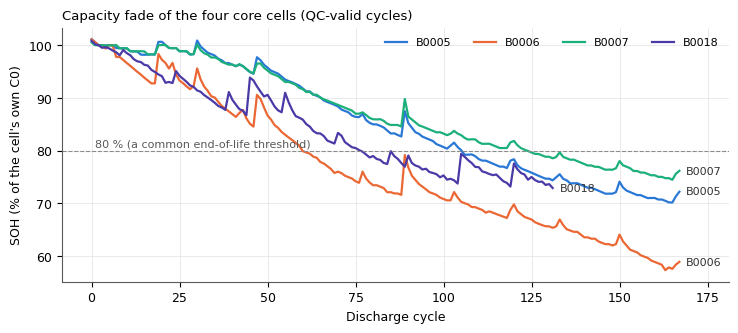

In [3]:
fig, ax = plt.subplots(figsize=(8.6, 3.3))
for battery, g in core.groupby("battery_id"):
    ax.plot(g["cycle_index"], g["soh_pct"], color=COLORS[battery], lw=1.6, label=battery)
    ax.annotate(
        battery,
        (g["cycle_index"].iloc[-1], g["soh_pct"].iloc[-1]),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=8,
        color="0.2",
    )
ax.axhline(80, color="0.55", lw=0.8, ls="--")
ax.text(1, 80.8, "80 % (a common end-of-life threshold)", fontsize=8, color="0.35")
ax.set_xlabel("Discharge cycle")
ax.set_ylabel("SOH (% of the cell's own C0)")
ax.set_title("Capacity fade of the four core cells (QC-valid cycles)", loc="left")
ax.set_xlim(right=core["cycle_index"].max() + 14)
ax.legend(loc="upper right", ncol=4)
plt.show()

The label is noisy at the cycle level: capacity partly recovers after rest periods, which shows
as upward jumps. B0006 starts with the largest initial capacity and fades the deepest, below
the range of every other core cell. Both facts matter in section 5.

## 3. The leakage trap, demonstrated

v1 of this project fed the measured capacity to the model. Within one cell, `C0` is a constant,
so the label is an exact linear function of that input:

In [4]:
within_r2 = {
    b: float(np.corrcoef(g["capacity_ah"], g["soh_pct"])[0, 1] ** 2)
    for b, g in core.groupby("battery_id")
}
identity_error = (100 * core["capacity_ah"] / core["c0_ah"] - core["soh_pct"]).abs().max()
print("within-battery R2(soh_pct, capacity_ah):", {b: round(v, 6) for b, v in within_r2.items()})
print(f"max |soh_pct - 100 * capacity_ah / c0_ah| = {identity_error:.1e}  (CSV rounding)")

within-battery R2(soh_pct, capacity_ah): {'B0005': 1.0, 'B0006': 1.0, 'B0007': 1.0, 'B0018': 1.0}
max |soh_pct - 100 * capacity_ah / c0_ah| = 6.9e-04  (CSV rounding)


**A v1-style model.** Ridge on the v1 inputs (`legacy_v1`: capacity, record length, whole-record
means, cycle count; loadable only with an explicit `allow_leaky=True`). As in v1, it is trained on
the first 85 % of B0005-B0007 and "tested" on *all* cycles of B0006 and B0007, so most test rows
are training rows. The same model family is then scored with leave-one-battery-out.

In [5]:
from battery_soh.evaluation.errors import LeakageError
from battery_soh.evaluation.metrics import regression_metrics, summarize_by_group
from battery_soh.evaluation.splits import (
    assert_disjoint,
    leave_one_group_out,
    row_keys,
    temporal_holdout,
)
from battery_soh.models.zoo import make_model


def lobo_predictions(data, features, factory=None):
    """Out-of-fold predictions: one fold per held-out battery, disjointness asserted."""
    factory = factory or partial(make_model, "ridge")
    yhat = np.full(len(data), np.nan)
    for train_idx, test_idx, _ in leave_one_group_out(data["battery_id"]):
        train, test = data.iloc[train_idx], data.iloc[test_idx]
        assert_disjoint(row_keys(train), row_keys(test))
        yhat[test_idx] = factory().fit(train[features], train["soh_pct"]).predict(test[features])
    return data[["battery_id", "cycle_index"]].assign(y=data["soh_pct"], yhat=yhat)


legacy = list(get_feature_set("legacy_v1", allow_leaky=True))  # explicit opt-in: audit only

v1 = core[core["battery_id"].isin(["B0005", "B0006", "B0007"])].reset_index(drop=True)
train_idx, _ = temporal_holdout(v1["battery_id"], v1["cycle_index"], test_fraction=0.15)
v1_train = v1.iloc[train_idx]
v1_model = make_model("ridge").fit(v1_train[legacy], v1_train["soh_pct"])

contaminated = v1[v1["battery_id"].isin(["B0006", "B0007"])]
train_keys = set(row_keys(v1_train))
seen = np.array([k in train_keys for k in row_keys(contaminated)])
pred = v1_model.predict(contaminated[legacy])
y = contaminated["soh_pct"].to_numpy()

lobo_v1 = summarize_by_group(lobo_predictions(core, legacy)).set_index("battery_id")
lobo_cap = summarize_by_group(
    lobo_predictions(core, list(get_feature_set("capacity_oracle", allow_leaky=True)))
).set_index("battery_id")

audit = json.loads((paths.reports / "audit" / "audit.json").read_text(encoding="utf-8"))
audit_mae = {row["id"]: row["mae"] for row in audit["rows"]}


def trap_row(name, n, n_seen, metrics, audit_id=None):
    return {
        "evaluation": name,
        "test rows": n,
        "seen in training": n_seen,
        "MAE (SOH pts)": metrics["mae"],
        "R2": metrics["r2"],
        "audit.json MAE": audit_mae.get(audit_id, np.nan),
    }


trap = pd.DataFrame(
    [
        trap_row(
            "v1 protocol: 'test' = all of B0006+B0007",
            len(y),
            int(seen.sum()),
            regression_metrics(y, pred),
            "v1_contaminated_split",
        ),
        trap_row(
            "  ... only the rows it was trained on",
            int(seen.sum()),
            int(seen.sum()),
            regression_metrics(y[seen], pred[seen]),
        ),
        trap_row(
            "  ... only the unseen rows",
            int((~seen).sum()),
            0,
            regression_metrics(y[~seen], pred[~seen]),
        ),
        trap_row(
            "leave-one-battery-out, same v1 inputs",
            len(core),
            0,
            {"mae": lobo_v1.loc["mean", "mae"], "r2": lobo_v1.loc["pooled", "r2"]},
            "v1_inputs_lobo",
        ),
        trap_row(
            "leave-one-battery-out, capacity alone",
            len(core),
            0,
            {"mae": lobo_cap.loc["mean", "mae"], "r2": lobo_cap.loc["pooled", "r2"]},
            "capacity_only_lobo",
        ),
    ]
).set_index("evaluation")
display(trap)

,test rows,seen in training,MAE (SOH pts),R2,audit.json MAE
evaluation,,,,,
v1 protocol: 'test' = all of B0006+B0007,336,284,1.208,0.977,1.208
... only the rows it was trained on,284,284,0.826,0.987,NaN
... only the unseen rows,52,0,3.295,0.795,NaN
"leave-one-battery-out, same v1 inputs",636,0,3.215,0.878,3.215
"leave-one-battery-out, capacity alone",636,0,3.473,0.857,3.473


The contaminated split looks excellent because it mostly re-scores training rows; the same model
is several times worse on rows it has not seen. Under leave-one-battery-out even *capacity itself*
is not a perfect input: `SOH = 100 * capacity / C0` and the held-out cell's `C0` is unknown. The
live numbers match the committed audit (`reports/audit/audit.json`, last column).

**Guards.** v2 makes each of these mistakes fail loudly:

In [6]:
from battery_soh.evaluation.leakage import (
    LABEL_CORRELATION_THRESHOLD,
    RECONSTRUCTION_R2_THRESHOLD,
    check_no_leakage,
)


def show_guard(label, call):
    try:
        call()
    except (LeakageError, ValueError) as exc:
        print(f"{label}\n  -> raises {type(exc).__name__}: {exc}\n")
    else:
        print(f"{label}\n  -> passed\n")


show_guard('get_feature_set("legacy_v1")', lambda: get_feature_set("legacy_v1"))
show_guard(
    "assert_disjoint(v1 training rows, v1 'test' rows)",
    lambda: assert_disjoint(row_keys(v1_train), row_keys(contaminated)),
)
show_guard("check_no_leakage(core, legacy_v1)", lambda: check_no_leakage(core, legacy))
combined = list(get_feature_set("combined"))
show_guard(
    'check_no_leakage(core, get_feature_set("combined"))', lambda: check_no_leakage(core, combined)
)
print(
    f"Thresholds: within-battery |r| >= {LABEL_CORRELATION_THRESHOLD}, "
    f"capacity reconstruction LOBO R2 >= {RECONSTRUCTION_R2_THRESHOLD}"
)

get_feature_set("legacy_v1")
  -> raises ValueError: Feature set 'legacy_v1' contains label-side/proxy features ['leg_capacity_ah', 'leg_record_time_s', 'leg_current_mean_a', 'leg_voltage_mean_v', 'leg_temp_max_c']; pass allow_leaky=True only for audits or labelled sanity baselines.

assert_disjoint(v1 training rows, v1 'test' rows)
  -> raises LeakageError: 284 evaluation row(s) also appear in the training data (e.g. ('B0006', 0), ('B0006', 1), ('B0006', 2), ('B0006', 3), ('B0006', 4))

check_no_leakage(core, legacy_v1)
  -> raises LeakageError: target leakage detected for label 'soh_pct':
  - leg_capacity_ah: registry: label-side feature; within-battery |r| with soh_pct = 1.00000 >= 0.9995; rebuilds capacity_ah alone (LOBO R2 = 1.00000 >= 0.995)
  - leg_record_time_s: registry: label proxy (full-discharge statistic)
  - leg_current_mean_a: registry: label proxy (full-discharge statistic)
  - leg_voltage_mean_v: registry: label proxy (full-discharge statistic)
  - leg_temp_max_c: regi

check_no_leakage(core, get_feature_set("combined"))
  -> passed

Thresholds: within-battery |r| >= 0.9995, capacity reconstruction LOBO R2 >= 0.995


## 4. Partial-window health indicators

An HI is a quantity measured on part of a cycle that is expected to track ageing. The
`combined` set has five charge-side HIs (measured on the constant-current / constant-voltage
charge) and three discharge-side HIs (measured inside the 3.80 V to 3.50 V window of a discharge,
about 40 % of a full discharge). Definitions come straight from the feature registry:

In [7]:
registry = pd.DataFrame(
    [
        {
            "feature": name,
            "unit": FEATURES[name].unit,
            "measured on": FEATURES[name].availability,
            "definition": FEATURES[name].description,
        }
        for name in combined
    ]
).set_index("feature")
display(registry)

,unit,measured on,definition
feature,,,
chg_cc_time_390_419_s,s,partial_charge,Time for the voltage to rise from 3.90 V to 4.19 V during constant-current charge.
chg_cv_time_s,s,partial_charge,Duration of the constant-voltage phase (V >= 4.19 V until current < 0.1 A).
chg_ica_peak_height_ah_per_v,Ah/V,partial_charge,"Height of the incremental-capacity (dQ/dV) peak on the CC charge segment, 3.90-4.18 V."
chg_ica_peak_voltage_v,V,partial_charge,Voltage at which the incremental-capacity peak occurs.
chg_temp_rise_cc_c,degC,partial_charge,Cell temperature rise between 3.90 V and 4.19 V in the CC charge phase.
dis_q_380_350_ah,Ah,partial_discharge,Charge delivered while the loaded voltage falls 3.80 V -> 3.50 V (~40% of a discharge).
dis_r0_ohm,ohm,partial_discharge,Ohmic resistance from the voltage step at load-on (dV/dI).
dis_temp_rise_win_c,degC,partial_discharge,Cell temperature rise inside the 3.80 V to 3.50 V discharge window.


In [8]:
from battery_soh.evaluation.leakage import leakage_report

report = leakage_report(core, combined).set_index("feature")
r_by_cell = pd.DataFrame(
    {b: g[combined].corrwith(g["soh_pct"]) for b, g in core.groupby("battery_id")}
)
hi_table = (
    r_by_cell.add_prefix("r ")
    .assign(
        **{
            "mean |r|": r_by_cell.abs().mean(axis=1),
            "LOBO R2 alone": report.loc[combined, "lobo_r2"],
            "rebuilds capacity R2": report.loc[combined, "capacity_reconstruction_r2"],
        }
    )
    .sort_values("mean |r|", ascending=False)
)
display(hi_table)
whole_set = report.loc["(feature set)"]
print(
    f"whole set: LOBO R2 {whole_set['lobo_r2']:.3f}, capacity reconstruction R2 "
    f"{whole_set['capacity_reconstruction_r2']:.3f} (flagged only at >= "
    f"{RECONSTRUCTION_R2_THRESHOLD})"
)

,r B0005,r B0006,r B0007,r B0018,mean |r|,LOBO R2 alone,rebuilds capacity R2
dis_q_380_350_ah,0.996,0.995,0.998,0.998,0.997,0.967,0.926
chg_cc_time_390_419_s,0.993,0.985,0.983,0.986,0.987,0.500,0.699
chg_ica_peak_height_ah_per_v,0.995,0.993,0.988,0.972,0.987,0.764,0.876
chg_cv_time_s,-0.983,-0.949,-0.976,-0.856,0.941,0.562,0.310
chg_ica_peak_voltage_v,-0.923,-0.991,-0.912,-0.893,0.930,0.688,0.415
dis_r0_ohm,-0.836,-0.958,-0.634,-0.896,0.831,0.340,0.168
dis_temp_rise_win_c,-0.812,-0.244,-0.236,0.023,0.329,-0.092,-0.101
chg_temp_rise_cc_c,0.145,-0.208,0.088,0.399,0.210,-0.168,-0.059


whole set: LOBO R2 0.883, capacity reconstruction R2 0.944 (flagged only at >= 0.995)


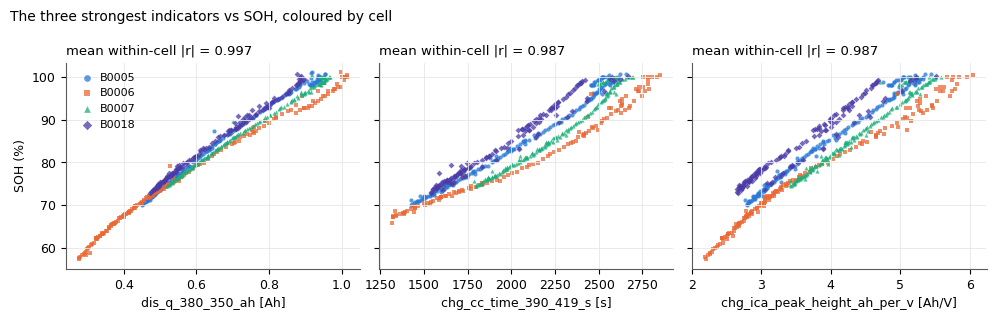

In [9]:
strongest = list(hi_table.index[:3])
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
for ax, name in zip(axes, strongest, strict=True):
    for battery, g in core.groupby("battery_id"):
        ax.scatter(
            g[name],
            g["soh_pct"],
            s=9,
            marker=MARKERS[battery],
            color=COLORS[battery],
            alpha=0.75,
            linewidths=0,
            label=battery,
        )
    ax.set_xlabel(f"{name} [{FEATURES[name].unit}]")
    ax.set_title(f"mean within-cell |r| = {hi_table.loc[name, 'mean |r|']:.3f}", loc="left")
axes[0].set_ylabel("SOH (%)")
axes[0].legend(loc="upper left", markerscale=1.6, handletextpad=0.2)
fig.suptitle(
    "The three strongest indicators vs SOH, coloured by cell", x=0.01, ha="left", fontsize=10
)
fig.tight_layout()
plt.show()

Within one cell the strongest HIs track SOH almost perfectly. That is what a health indicator is
for, so high correlation alone is not leakage; the guard targets *exact* reconstructions. Across
cells each HI carries a cell-specific offset (the clouds do not overlap perfectly), which is why the
univariate leave-one-battery-out R² is lower than the within-cell correlation suggests. That offset
is the main error source in the next section.

## 5. Honest evaluation

Leave-one-battery-out with `make_model("ridge")` (median imputation, standardisation, Ridge with
`alpha=1`) on the `discharge` and `combined` sets, next to two baselines a model must beat: the
training mean and a ridge on the cycle count alone. The last column is the same configuration read
back from the committed benchmark (`reports/benchmark/summary.json`).

In [10]:
from battery_soh.evaluation.baselines import baseline_features, make_baseline

summary = json.loads((paths.benchmark_dir / "summary.json").read_text(encoding="utf-8"))
secondary = {(r["feature_set"], r["mode"], r["model"]): r for r in summary["secondary"]}

specs = {
    "Ridge, discharge HIs": (
        partial(make_model, "ridge"),
        list(get_feature_set("discharge")),
        secondary[("discharge", "absolute", "ridge")]["mae"],
    ),
    "Ridge, combined HIs": (
        partial(make_model, "ridge"),
        combined,
        secondary[("combined", "absolute", "ridge")]["mae"],
    ),
    "Baseline: training mean": (
        partial(make_baseline, "mean"),
        ["ctx_cycle_index"],
        summary["baselines"]["mean"]["mae"],
    ),
    "Baseline: cycle count only": (
        partial(make_baseline, "cycle_only"),
        list(baseline_features("cycle_only")),
        summary["baselines"]["cycle_only"]["mae"],
    ),
}
rows = {}
for name, (factory, features, bench_mae) in specs.items():
    s = summarize_by_group(lobo_predictions(core, features, factory)).set_index("battery_id")
    rows[name] = {
        **{f"MAE {b}": s.loc[b, "mae"] for b in CORE_BATTERIES},
        "mean MAE": s.loc["mean", "mae"],
        "pooled R2": s.loc["pooled", "r2"],
        "benchmark mean MAE": bench_mae,
    }
live = pd.DataFrame(rows).T
display(live)

,MAE B0005,MAE B0006,MAE B0007,MAE B0018,mean MAE,pooled R2,benchmark mean MAE
"Ridge, discharge HIs",1.001,2.657,1.251,1.699,1.652,0.965,1.652
"Ridge, combined HIs",1.013,5.833,1.166,2.372,2.596,0.898,2.596
Baseline: training mean,9.356,13.548,8.083,7.464,9.613,-0.121,9.613
Baseline: cycle count only,3.897,8.290,6.369,2.665,5.305,0.653,5.305


### The pre-specified headline

The headline is the `combined` set in absolute mode with *nested* feature selection (`ridge_nfs`:
inside every outer fold, greedy backward elimination and the ridge penalty are chosen by an inner
leave-one-battery-out over the training cells only). It was written into `configs/benchmark.yaml`
before any `ridge_nfs` result was computed, and it is reported unchanged.

It was not chosen blind to these four cells: the indicator windows, feature sets and relative mode
come from an audit prototype that had already scored plain Ridge leave-one-battery-out on them
(MAE about 1.6-1.7), and plain-Ridge results for this same `combined`/absolute specification on the
v2 table (2.60; B0006 5.83, the second row of the table above), the no-CV-time ablation and
relative mode were known when the headline was fixed. The declaration guards against picking the
best of the 114 leaderboard rows afterwards; it does not make the design independent of these
cells. All numbers below are read from `summary.json`; R² is pooled over all held-out
predictions, the other metrics are averaged over held-out cells.

In [11]:
head = summary["headline"]
spec = " / ".join(head[k] for k in ("experiment", "feature_set", "mode", "model"))
display(
    Markdown(
        f"**Headline** `{spec}`: MAE **{head['mae']:.2f}** SOH points (mean over "
        f"{head['n_batteries']} held-out cells, {head['n']} cycles), RMSE {head['rmse']:.2f}, "
        f"pooled R² {head['r2']:.3f}, worst cell {head['worst_battery']} "
        f"(MAE {head['worst_mae']:.2f}). 90 % interval coverage {head['coverage_90']:.2f} "
        f"(mean width {head['mean_width_90']:.1f} SOH points)."
    )
)
base = summary["baselines"]
print(
    f"Baselines (LOBO MAE): training mean {base['mean']['mae']:.2f} | "
    f"cycle count only {base['cycle_only']['mae']:.2f} | "
    f"capacity oracle {base['capacity_oracle']['mae']:.2f} (LEAKY, sanity check only)"
)
per_battery = pd.DataFrame(summary["per_battery"]).set_index("battery_id")
columns = ["n", "mae", "rmse", "r2", "bias", "max_abs_error", "coverage_90", "mean_width_90"]
display(per_battery[columns])

**Headline** `core_lobo / combined / absolute / ridge_nfs`: MAE **2.53** SOH points (mean over 4 held-out cells, 636 cycles), RMSE 2.84, pooled R² 0.881, worst cell B0006 (MAE 6.45). 90 % interval coverage 0.74 (mean width 9.8 SOH points).

Baselines (LOBO MAE): training mean 9.61 | cycle count only 5.30 | capacity oracle 3.47 (LEAKY, sanity check only)


,n,mae,rmse,r2,bias,max_abs_error,coverage_90,mean_width_90
battery_id,,,,,,,,
B0005,168,1.016,1.209,0.986,-0.045,4.437,1.000,16.383
B0006,168,6.455,6.975,0.688,6.419,12.979,0.000,3.687
B0007,168,1.424,1.494,0.969,1.295,3.013,1.000,10.963
B0018,132,1.210,1.667,0.961,-0.404,7.115,0.947,8.082


### Why B0006 fails: over-estimation from cell-specific offsets

B0006 is the only cell with a large error, and its `bias` (mean of prediction minus truth) is
almost equal to its MAE: the model **over-estimates** B0006 nearly everywhere. Two mechanisms,
both visible in the data:

1. **Absolute indicators measure absolute charge and time, while the label is relative to the
   cell's own `C0`.** B0006 has the largest `C0` (section 2), so over most of the SOH range its
   discharge window delivers more Ah than the other cells' windows at the same SOH (first panel
   of the section 4 figure).
2. **The CV-phase duration has a cell-specific offset.** At the same SOH, B0006 spends longer in
   constant-voltage charge (right panel). In a ridge fitted on the other three cells the CV-time
   coefficient takes the *opposite* sign to its marginal correlation with SOH (a collinearity
   effect), so that offset is converted into extra predicted SOH.

,marginal r with SOH (training cells),ridge coefficient (fold without B0006)
chg_cv_time_s,-0.908,1.683
dis_q_380_350_ah,0.991,9.975
chg_cc_time_390_419_s,0.961,1.425


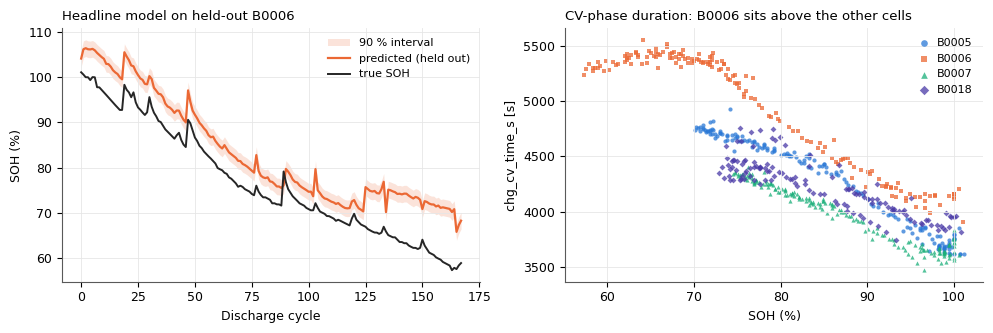

In [12]:
held_out = "B0006"
train_cells = core[core["battery_id"] != held_out]
fold_model = make_model("ridge").fit(train_cells[combined], train_cells["soh_pct"])
coef = pd.Series(fold_model[-1].coef_, index=combined)
signs = pd.DataFrame(
    {
        "marginal r with SOH (training cells)": train_cells[combined].corrwith(
            train_cells["soh_pct"]
        ),
        "ridge coefficient (fold without B0006)": coef,
    }
).loc[["chg_cv_time_s", "dis_q_380_350_ah", "chg_cc_time_390_419_s"]]
display(signs)

pred = pd.DataFrame(summary["predictions"])
b6 = pred[pred["battery_id"] == held_out]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
ax1.fill_between(
    b6["cycle_index"],
    b6["lo_90"],
    b6["hi_90"],
    color=COLORS[held_out],
    alpha=0.18,
    linewidth=0,
    label="90 % interval",
)
ax1.plot(
    b6["cycle_index"], b6["yhat"], color=COLORS[held_out], lw=1.6, label="predicted (held out)"
)
ax1.plot(b6["cycle_index"], b6["y"], color="0.15", lw=1.4, label="true SOH")
ax1.set_xlabel("Discharge cycle")
ax1.set_ylabel("SOH (%)")
ax1.set_title(f"Headline model on held-out {held_out}", loc="left")
ax1.legend(loc="upper right")
for battery, g in core.groupby("battery_id"):
    ax2.scatter(
        g["soh_pct"],
        g["chg_cv_time_s"],
        s=9,
        marker=MARKERS[battery],
        color=COLORS[battery],
        alpha=0.75,
        linewidths=0,
        label=battery,
    )
ax2.set_xlabel("SOH (%)")
ax2.set_ylabel("chg_cv_time_s [s]")
ax2.set_title("CV-phase duration: B0006 sits above the other cells", loc="left")
ax2.legend(loc="upper right", markerscale=1.6, handletextpad=0.2)
fig.tight_layout()
plt.show()

Two remedies were evaluated, both read from `summary.json`. Dropping the CV time is a *post-hoc*
ablation (defined after seeing these results), so it is reported as a diagnostic, not as a model
choice. *Relative mode* divides each indicator by the cell's own mean over its first five valid
cycles (a commissioning reference), which largely removes both offsets; those reference
cycles are excluded from scoring. Relative mode appears twice below: with plain Ridge (the model
in the README's trajectory figure and the audit table) and with nested selection (the procedure
of the shipped `combined-relative-ridge` bundle).

In [13]:
rel_head = summary["relative_headline"]
remedies = [
    ("pre-specified headline", head),
    ("same set, plain ridge", secondary[("combined", "absolute", "ridge")]),
    (
        "post-hoc ablation: combined without CV time",
        secondary[("combined_no_cv", "absolute", "ridge")],
    ),
    ("relative mode, plain ridge", rel_head),
    ("relative mode, nested selection", secondary[("combined", "relative", "ridge_nfs")]),
]
display(
    pd.DataFrame(
        [
            {
                "variant": label,
                "spec": f"{r['feature_set']}/{r['mode']}/{r['model']}",
                "mean MAE": r["mae"],
                "worst cell": r["worst_battery"],
                "worst MAE": r["worst_mae"],
                "coverage 90%": r["coverage_90"],
                "post hoc": r["post_hoc"],
            }
            for label, r in remedies
        ]
    ).set_index("variant")
)

,spec,mean MAE,worst cell,worst MAE,coverage 90%,post hoc
variant,,,,,,
pre-specified headline,combined/absolute/ridge_nfs,2.526,B0006,6.455,0.737,False
"same set, plain ridge",combined/absolute/ridge,2.596,B0006,5.833,0.751,False
post-hoc ablation: combined without CV time,combined_no_cv/absolute/ridge,1.652,B0006,2.448,0.844,True
"relative mode, plain ridge",combined/relative/ridge,1.080,B0006,1.850,0.865,False
"relative mode, nested selection",combined/relative/ridge_nfs,1.021,B0006,1.263,0.927,False


### Beyond the four reference cells

The extended benchmark holds out each of 12 usable cells from three operating conditions
(leave-one-battery-out), and then each whole condition (leave-one-condition-out, a much harder
extrapolation). Conditions differ in load and temperature, so the extended sets add the ambient
temperature and load current as context inputs (`*_ext`).

In [14]:
keep = [
    "experiment",
    "feature_set",
    "mode",
    "model",
    "mae",
    "worst_battery",
    "worst_mae",
    "coverage_90",
]
ext = pd.DataFrame(summary["extended"]["results"])
loco = pd.DataFrame(summary["loco"]["results"])
linear = ["ridge", "ridge_nfs", "mean", "cycle_only"]
display(
    ext[ext["model"].isin(linear)][keep]
    .sort_values(["mode", "mae"], ascending=[False, True])
    .set_index(["experiment", "feature_set", "mode", "model"])
)
display(
    loco[loco["model"].isin(["ridge", "ridge_nfs", "mean"])][keep[:-1]]
    .sort_values(["mode", "mae"], ascending=[False, True])
    .set_index(["experiment", "feature_set", "mode", "model"])
)
best = (
    pd.DataFrame(summary["extended"]["results"])
    .query("feature_set == 'combined_ext' and mode == 'relative' and model == 'ridge_nfs'")
    .iloc[0]
)
print(
    "per-condition MAE, combined_ext / relative / ridge_nfs:",
    {c: round(v["mae"], 2) for c, v in best["per_condition"].items()},
)
wilcoxon = pd.DataFrame(summary["extended"]["wilcoxon"])
display(
    wilcoxon[
        [
            "feature_set",
            "mode",
            "mae_reference",
            "best_candidate",
            "mae_best_candidate",
            "n_pairs",
            "p_value",
        ]
    ]
    .rename(columns={"mae_reference": "ridge MAE"})
    .set_index(["feature_set", "mode"])
)

mae worst_battery  \
experiment    feature_set  mode     model                             
extended_lobo combined_ext relative ridge_nfs   1.960         B0032   
                                    ridge       2.067         B0032   
              charge_ext   relative ridge_nfs   2.837         B0047   
                                    ridge       2.864         B0047   
              baseline     relative cycle_only  5.692         B0036   
                                    mean        8.088         B0006   
              charge_ext   absolute ridge_nfs   4.181         B0047   
                                    ridge       4.278         B0047   
              combined_ext absolute ridge_nfs   4.613         B0036   
                                    ridge       4.735         B0036   
              baseline     absolute cycle_only  5.624         B0036   
                                    mean        8.335         B0006   

                                                worst_mae  coverage_90  
experiment    feature_set  mode     model                               
extended_lobo combined_ext relative ridge_nfs       4.655        0.811  
                                    ridge           3.791        0.834  
              charge_ext   relative ridge_nfs       4.927        0.911  
                                    ridge           5.236        0.910  
              baseline     relative cycle_only     15.928          NaN  
                                    mean           14.692          NaN  
              charge_ext   absolute ridge_nfs       9.084        0.891  
                                    ridge           8.873        0.898  
              combined_ext absolute ridge_nfs      13.072        0.912  
                                    ridge          14.359        0.910  
              baseline     absolute cycle_only     15.607          NaN  
                                    mean           14.975          NaN

mae worst_battery  \
experiment              feature_set  mode     model                             
leave_one_condition_out combined_ext relative ridge_nfs   2.778         B0032   
                                              ridge       3.207         B0029   
                        charge_ext   relative ridge       6.072         B0047   
                        baseline     relative mean        8.200         B0006   
                        charge_ext   relative ridge_nfs  23.138         B0030   
                        baseline     absolute mean        8.521         B0006   
                        combined_ext absolute ridge_nfs  19.438         B0007   
                        charge_ext   absolute ridge      20.118         B0046   
                                              ridge_nfs  21.100         B0030   
                        combined_ext absolute ridge      21.428         B0031   

                                                         worst_mae  
experiment              feature_set  mode     model                 
leave_one_condition_out combined_ext relative ridge_nfs      6.384  
                                              ridge          6.563  
                        charge_ext   relative ridge         12.520  
                        baseline     relative mean          14.966  
                        charge_ext   relative ridge_nfs     58.703  
                        baseline     absolute mean          15.508  
                        combined_ext absolute ridge_nfs     26.062  
                        charge_ext   absolute ridge         34.512  
                                              ridge_nfs     38.153  
                        combined_ext absolute ridge         27.463

per-condition MAE, combined_ext / relative / ridge_nfs: {'1A_4C': 1.42, '2A_24C': 1.26, '4A_43C': 3.24}


,,ridge MAE,best_candidate,mae_best_candidate,n_pairs,p_value
feature_set,mode,,,,,
charge_ext,relative,2.864,hgb,2.538,12,0.204
combined_ext,relative,2.067,hgb,1.369,12,0.042
charge_ext,absolute,4.278,gpr,4.977,12,0.233
combined_ext,absolute,4.735,hgb,3.575,12,0.301


In absolute mode, cell-to-cell and condition-to-condition offsets dominate the error; under
leave-one-condition-out the absolute-mode ridge models are worse than the training-mean baseline.
Relative mode with the `combined_ext` set transfers best, while the charge-only sets stay fragile
(see `ridge_nfs` on `charge_ext` under leave-one-condition-out). The last table compares ridge with
the better of two non-linear models (`gpr`, `hgb`) per setting: a paired two-sided Wilcoxon test
over the 12 held-out cells, uncorrected, where picking the best candidate on the same folds favours
the candidate. The one p-value below 0.05 (HGB on `combined_ext`, relative mode) is about 0.085
after a factor-2 correction for that choice, and it moves with the library version (0.021 under
scikit-learn 1.9.1 instead of the pinned 1.8.0), so the difference is suggestive, not established.

## 6. Uncertainty

`GroupConformalRegressor` calibrates intervals on *battery-level* residuals: inside the training
cells it runs its own leave-one-battery-out, so every calibration residual comes from a cell the
fold model never saw. Nested in an outer leave-one-battery-out on the `discharge` set, the held-out
cell never touches fitting or calibration. `cv` is the fixed half-width the production bundle ships;
`cv_plus` is group CV+ (Barber et al., 2021).

In [15]:
from battery_soh.evaluation.metrics import interval_metrics
from battery_soh.uncertainty.conformal import GroupConformalRegressor

discharge = list(get_feature_set("discharge"))
alpha = 0.10
records = []
for train_idx, test_idx, held in leave_one_group_out(core["battery_id"]):
    train, test = core.iloc[train_idx], core.iloc[test_idx]
    for method in ("cv", "cv_plus"):
        gcr = GroupConformalRegressor(partial(make_model, "ridge"), method=method)
        gcr.fit(train[discharge], train["soh_pct"], train["battery_id"])
        _, lo, hi = gcr.predict_interval(test[discharge], alpha=alpha)
        m = interval_metrics(test["soh_pct"], lo, hi, alpha=alpha)
        records.append(
            {
                "held-out cell": held,
                "method": method,
                "coverage": m["coverage"],
                "truth below interval": m["below"],
                "truth above interval": m["above"],
                "mean width": m["mean_width"],
                "calibration scores": gcr.n_scores_,
            }
        )
cov = pd.DataFrame(records).set_index(["held-out cell", "method"]).unstack("method")
cov.loc["mean"] = cov.mean()
display(cov[["coverage", "truth below interval", "mean width"]])

coverage         truth below interval         mean width        
method              cv cv_plus                   cv cv_plus         cv cv_plus
held-out cell                                                                 
B0005            0.994   1.000                 0.00   0.000      9.628  10.274
B0006            0.440   0.649                 0.56   0.351      4.331   5.596
B0007            0.994   1.000                 0.00   0.000      7.326   7.942
B0018            0.947   0.962                 0.00   0.000      6.407   7.434
mean             0.844   0.903                 0.14   0.088      6.923   7.811

Three cells are covered at or above the 90 % target; B0006 is not, and its misses fall on one
side (truth *below* the interval: the over-estimation from section 5). This is the method's limit
showing, not a bug. Conformal coverage is an average over new cells that are **exchangeable** with
the calibration cells, and with three calibration cells per fold there is no battery-level
finite-sample guarantee even then (a 90 % guarantee needs at least nine cells): coverage here is an
empirical property, measured on held-out cells. The three calibration cells transfer well to each
other, so their residuals are small, and the half-width cannot anticipate a fourth cell whose
systematic offset exceeds it. With four cells one atypical cell is a quarter of the population. The shipped bundle pools residuals from all four cells (B0006 included),
which widens its interval.

## 7. Using the shipped model

Production models are plain JSON bundles (no pickle), listed with SHA-256 digests in
`artifacts/models/MANIFEST.json` and evaluated with a NumPy-only runtime (`LinearBundle`). The
service loads exactly these files. Each bundle is the benchmark's training procedure (nested
feature and penalty selection, then a ridge fit) refitted on all four core cells; the metrics it
carries are that procedure's leave-one-battery-out results. The cells below verify the manifest,
load the `discharge` bundle and explain one prediction. B0007 is one of the bundle's training cells,
so that prediction is in-sample: it shows the mechanics (interval, additive explanation, domain
check), not accuracy on a new cell, which is what the leave-one-battery-out numbers above measure.

In [16]:
from battery_soh.models.linear_bundle import LinearBundle, verify_manifest

bundle = None
bundle_path = paths.models_dir / "discharge-absolute-ridge.json"
if (paths.models_dir / "MANIFEST.json").is_file() and bundle_path.is_file():
    verified = verify_manifest(paths.models_dir)  # raises ManifestError on any mismatch
    width = max(map(len, verified))
    for name, digest in verified.items():
        print(f"sha256 OK  {name:{width}s}  {digest[:16]}...")
    bundle = LinearBundle.from_json(bundle_path)
    print(f"\n{bundle!r}")
    print("inputs:", ", ".join(bundle.features))
    print(
        f"90 % conformal half-width: +/- {bundle.half_width(0.9):.2f} SOH points "
        f"({bundle.n_scores} calibration residuals)"
    )
    lobo = bundle.metrics.get("mean", {})
    coverage = bundle.metrics.get("coverage", {})
    if lobo:
        print(
            f"recorded LOBO evaluation: MAE {lobo['mae']:.2f}, worst cell "
            f"{lobo['worst_battery']} ({lobo['worst_mae']:.2f}), "
            f"90 % coverage {coverage.get('0.9', float('nan')):.2f}"
        )
else:
    print(
        f"{rel(paths.models_dir)} holds no bundles yet: run `soh train`, then re-run this "
        "notebook. The calls below are skipped until the bundles exist."
    )

sha256 OK  charge-absolute-ridge.json               de9315490067b6dc...
sha256 OK  combined-absolute-ridge.json             b768c306aa53c40a...
sha256 OK  combined-relative-ridge.json             8c7519b9e74d012c...
sha256 OK  discharge-absolute-ridge.json            56a19ff034c0eeeb...
sha256 OK  model_cards/charge-absolute-ridge.md     9733102f22c67d53...
sha256 OK  model_cards/combined-absolute-ridge.md   b2baf848e0c5c62c...
sha256 OK  model_cards/combined-relative-ridge.md   f1f4477674b4525d...
sha256 OK  model_cards/discharge-absolute-ridge.md  563a1f8d752d25dd...

LinearBundle(model_id='discharge-absolute-ridge', feature_set='discharge', mode='absolute', n_features=2)
inputs: dis_q_380_350_ah, dis_r0_ohm
90 % conformal half-width: +/- 3.36 SOH points (636 calibration residuals)
recorded LOBO evaluation: MAE 1.71, worst cell B0006 (2.51), 90 % coverage 0.84


In [17]:
def estimate(row, confidence=0.9):
    """Predict one feature-table row with the bundle; print SOH, interval and truth."""
    inputs = {name: float(row[name]) for name in bundle.features}
    soh = bundle.predict(inputs)
    lower, upper = bundle.interval(soh, confidence)
    print(
        f"{row['battery_id']} cycle {row['cycle_index']}: predicted SOH {soh:.2f} %, "
        f"{confidence * 100:.0f} % interval [{lower:.2f}, {upper:.2f}], true {row['soh_pct']:.2f} %"
    )
    return inputs, soh


def show_domain(inputs):
    """Print the bundle's applicability check for one input."""
    d = bundle.domain_check(inputs)
    print(
        f"domain check: in_domain={d.in_domain}, out_of_range={list(d.out_of_range)}, "
        f"Mahalanobis distance {d.mahalanobis:.2f} (threshold {d.threshold:.2f})"
    )


if bundle is not None:
    # A mid-life cycle of a core cell (one of the bundle's training cells).
    row = core[(core["battery_id"] == "B0007") & (core["cycle_index"] == 80)].iloc[0]
    inputs, soh = estimate(row)
    contributions = pd.DataFrame(
        bundle.contributions(inputs), columns=["feature", "value", "contribution (SOH pts)"]
    ).set_index("feature")
    display(contributions)
    total = bundle.base_value + contributions["contribution (SOH pts)"].sum()
    print(
        f"additivity: base value {bundle.base_value:.4f} + sum of contributions = {total:.6f}, "
        f"prediction = {soh:.6f}, equal: {np.isclose(total, soh, rtol=0, atol=1e-9)}"
    )
    show_domain(inputs)
    print("\nrequest body for POST /v1/soh/estimate:")
    body = {"features": inputs, "model_id": bundle.model_id, "confidence": 0.9}
    print(json.dumps(body, indent=2))

B0007 cycle 80: predicted SOH 86.72 %, 90 % interval [83.36, 90.09], true 85.95 %


,value,contribution (SOH pts)
feature,,
dis_q_380_350_ah,0.706,2.183
dis_r0_ohm,0.099,0.943


additivity: base value 83.5982 + sum of contributions = 86.724863, prediction = 86.724863, equal: True
domain check: in_domain=True, out_of_range=[], Mahalanobis distance 0.77 (threshold 2.91)

request body for POST /v1/soh/estimate:
{
  "features": {
    "dis_q_380_350_ah": 0.705951,
    "dis_r0_ohm": 0.099328
  },
  "model_id": "discharge-absolute-ridge",
  "confidence": 0.9
}


The domain check is the model's guard against inputs unlike its training data (per-feature range
with a margin, plus a Mahalanobis distance). B0036 is a 2 A / 24 °C cell from a later test
campaign that the bundle never saw; its ohmic resistance is higher than any core cell's:

In [18]:
if bundle is not None:
    unseen = table[(table["battery_id"] == "B0036") & table["qc_valid"]]
    inputs_unseen, _ = estimate(unseen[unseen["cycle_index"] == 90].iloc[0])
    show_domain(inputs_unseen)
    print(
        "dis_r0_ohm range of the four core cells: "
        f"{core['dis_r0_ohm'].min():.4f} to {core['dis_r0_ohm'].max():.4f} ohm"
    )

B0036 cycle 90: predicted SOH 74.52 %, 90 % interval [71.16, 77.88], true 95.01 %
domain check: in_domain=False, out_of_range=['dis_r0_ohm'], Mahalanobis distance 6.16 (threshold 2.91)
dis_r0_ohm range of the four core cells: 0.0914 to 0.1316 ohm


The estimate is far off, and the bundle says so: the input is outside the training domain. The API
returns this flag with every response (`domain.in_domain`, plus an entry in `warnings`), so a client
can refuse to act on such an estimate.

**Same call over HTTP.** `soh serve` starts the FastAPI service (and the web UI) on
`http://127.0.0.1:8000`; OpenAPI docs are at `/docs`. The request for the B0007 cycle above:

```bash
curl -s http://127.0.0.1:8000/v1/soh/estimate \
  -H "Content-Type: application/json" \
  -d '{"features": {"dis_q_380_350_ah": 0.705951, "dis_r0_ohm": 0.099328},
       "model_id": "discharge-absolute-ridge", "confidence": 0.9}'
```

The response (abridged) carries the same quantities as above:

```json
{"model_id": "discharge-absolute-ridge", "soh_pct": ...,
 "interval": {"lower": ..., "upper": ..., "confidence": 0.9, "method": "..."},
 "base_value": ..., "contributions": [{"feature": "...", "value": ..., "contribution": ...}],
 "domain": {"in_domain": true, "out_of_range": [], "mahalanobis": ..., "threshold": ...},
 "warnings": []}
```

`POST /v1/soh/estimate-from-cycle` takes raw charge/discharge arrays instead and runs the same
feature extractor that built the training table (train/serve parity).

## 8. Where to go next

- [README](../README.md): quick start, API, web UI, results summary.
- [docs/LEAKAGE_AUDIT.md](../docs/LEAKAGE_AUDIT.md): the full v1 audit and how each failure mode is
  now guarded.
- [docs/METHODOLOGY.md](../docs/METHODOLOGY.md): label definition, indicators, protocol, conformal
  intervals and their assumptions.
- `reports/benchmark/summary.json`, `reports/audit/audit.json`: every number in this notebook.
- Reproduce them: `soh audit`, `soh benchmark` (full grid, tens of minutes) or
  `soh benchmark --quick` (headline subset, written to `reports/benchmark/quick/`).
- The v1 notebooks are archived, unmaintained, in `legacy/notebooks/`.